# Softmax Scale (`l`) Sensitivity — GempyHSI Integrated Bayesian Likelihood

Illustrates how the softmax "sharpness" parameter `l` in
`gamma_nk = softmax(l * (custom_grid_value - cluster_position)^2)`
controls the per-cluster assignment confidence, for an idealized 1D
grid of `K` clusters at unit spacing.

For each cluster `C_i` (i = 1..K), this shows how the softmax
probability of belonging to `C_i` varies across the domain `x`, for a
range of `l` values -- the same mechanism used in
`integrated_bayesian.py`'s likelihood, just visualized in isolation
from the rest of the geological model.

In [12]:
import numpy as np
import matplotlib.pyplot as plt

def softmax_probs(x, cluster_positions, l):
    """
    Softmax assignment probabilities for a single point x across all
    clusters in cluster_positions, at sharpness l.

    l == 0 is handled as the uniform-probability limit (no information),
    matching the l -> 0 limit of the softmax (all logits equal).
    """
    d2 = (x - cluster_positions) ** 2
    if l == 0:
        K = len(cluster_positions)
        return np.full(K, 1.0 / K)
    logits = -l * d2
    logits = logits - logits.max()  # numerical stability
    probs = np.exp(logits)
    return probs / probs.sum()

def softmax_grad(x, cluster_positions, l):
    """
    Analytic gradient dC_i/dx of the softmax assignment probabilities
    w.r.t. x, for each cluster i, at sharpness l.

    dC_i/dx = 2*l*C_i*(mu_i - <mu>_C),
    where <mu>_C = sum_j C_j * mu_j is the softmax-weighted mean
    cluster position at this x.

    l == 0 gives zero gradient everywhere, matching the l -> 0 limit
    of softmax_probs (uniform probabilities, independent of x).
    """
    cluster_positions = np.asarray(cluster_positions, dtype=float)
    if l == 0:
        return np.zeros_like(cluster_positions)
    C = softmax_probs(x, cluster_positions, l)
    mu_bar = np.sum(C * cluster_positions)
    return 2 * l * C * (cluster_positions - mu_bar)

In [13]:
def softmax_grad_numeric(x, cluster_positions, l, eps=1e-6):
    f_plus = softmax_probs(x + eps, cluster_positions, l)
    f_minus = softmax_probs(x - eps, cluster_positions, l)
    return (f_plus - f_minus) / (2 * eps)

# check they agree
x_test, cp_test, l_test = 1.3, np.array([1.0, 1.5, 2.0]), 10.0
print(softmax_grad(x_test, cp_test, l_test))
print(softmax_grad_numeric(x_test, cp_test, l_test))

[-2.36936904  2.27541733  0.09395171]
[-2.36936904  2.27541733  0.09395171]


## Parameters

- `K` — number of clusters (e.g. 6 for SalinasA, 3 for KSL/synthetic).
- `n_points` — resolution of the `x` grid via `np.linspace`.
- `l_values` — the scale/sharpness values to compare.

In [14]:
K = 6                                 # number of clusters
n_points = 10000                         # resolution of the x grid
l_values = [1, 5, 10, 15, 20, 25, 30]  # scale values to compare

cluster_positions = np.arange(1, K + 1)
x_values = np.linspace(0.5, 6 + 0.5, n_points)

print(f"K = {K} clusters at positions {cluster_positions.tolist()}")
print(f"x grid: {n_points} points from {x_values[0]} to {x_values[-1]}")
print(f"l values: {l_values}")


K = 6 clusters at positions [1, 2, 3, 4, 5, 6]
x grid: 10000 points from 0.5 to 6.5
l values: [1, 5, 10, 15, 20, 25, 30]


## Compute probabilities

For each cluster `C_i` and each `l`, evaluate `P(cluster = C_i | x)`
across the full `x` grid.

In [15]:
# probs[l][i] = array of P(cluster = C_{i+1}) across x_values, for scale l
probs = {
    l: np.array([softmax_probs(x, cluster_positions, l) for x in x_values])
    for l in l_values
}
# probs[l] has shape (n_points, K); probs[l][:, i] is C_{i+1}'s curve

# grads[l][i] = array of dC_i/dx across x_values, for scale l
grads = {
    l: np.array([softmax_grad(x, cluster_positions, l) for x in x_values])
    for l in l_values
}
# grads[l] has shape (n_points, K); grads[l][:, i] is dC_{i+1}/dx's curve

## Plot: K rows, one per cluster `C_i`

Each row shows `P(cluster = C_i)` vs. `x`, with one line per `l` value.
All clusters share the same shape (a peak at their own center,
sharpening as `l` increases) -- only the edge clusters (`C_1`, `C_K`)
look slightly different since they only have one neighbor instead of
two.

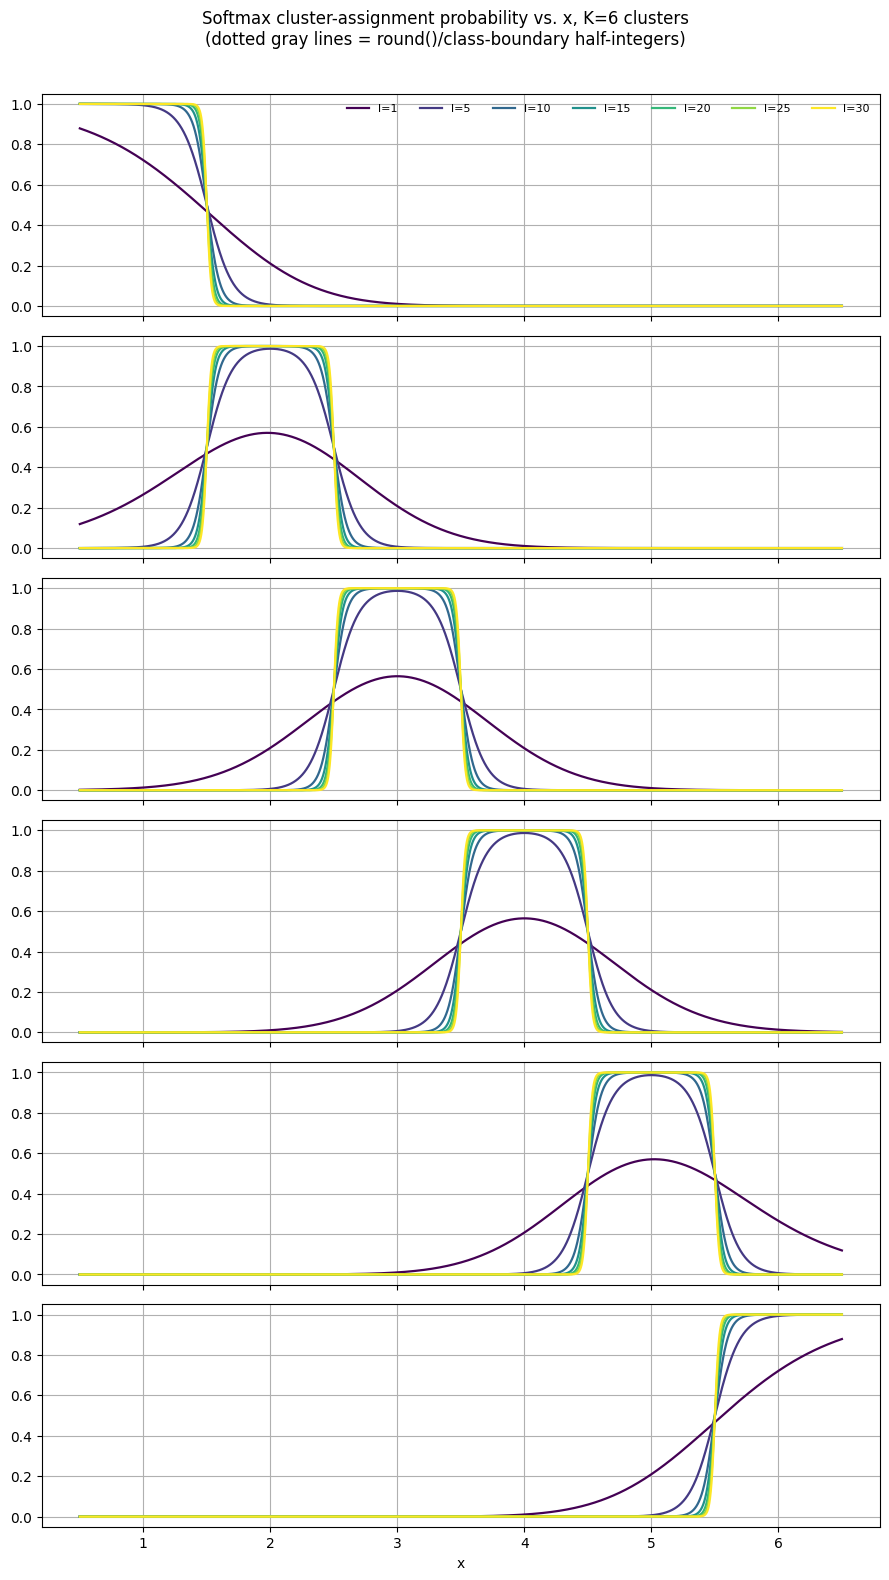

In [16]:
fig, axes = plt.subplots(K, 1, figsize=(9, 2.6 * K), sharex=True)
if K == 1:
    axes = [axes]

colors = plt.cm.viridis(np.linspace(0, 1, len(l_values)))

for i, ax in enumerate(axes):
    for l, color in zip(l_values, colors):
        
        ax.plot(x_values, probs[l][:, i], label=f"l={l}", color=color, linewidth=1.6)
        ax.grid()
    
axes[0].legend(loc="upper right", ncol=len(l_values), fontsize=8, frameon=False)
axes[-1].set_xlabel("x")
fig.suptitle(
    f"Softmax cluster-assignment probability vs. x, K={K} clusters\n"
    f"(dotted gray lines = round()/class-boundary half-integers)",
    y=1.01,
)
fig.tight_layout()

#plt.savefig("softmax_scale_sensitivity_K{}.png".format(K), dpi=150, bbox_inches="tight")
plt.show()


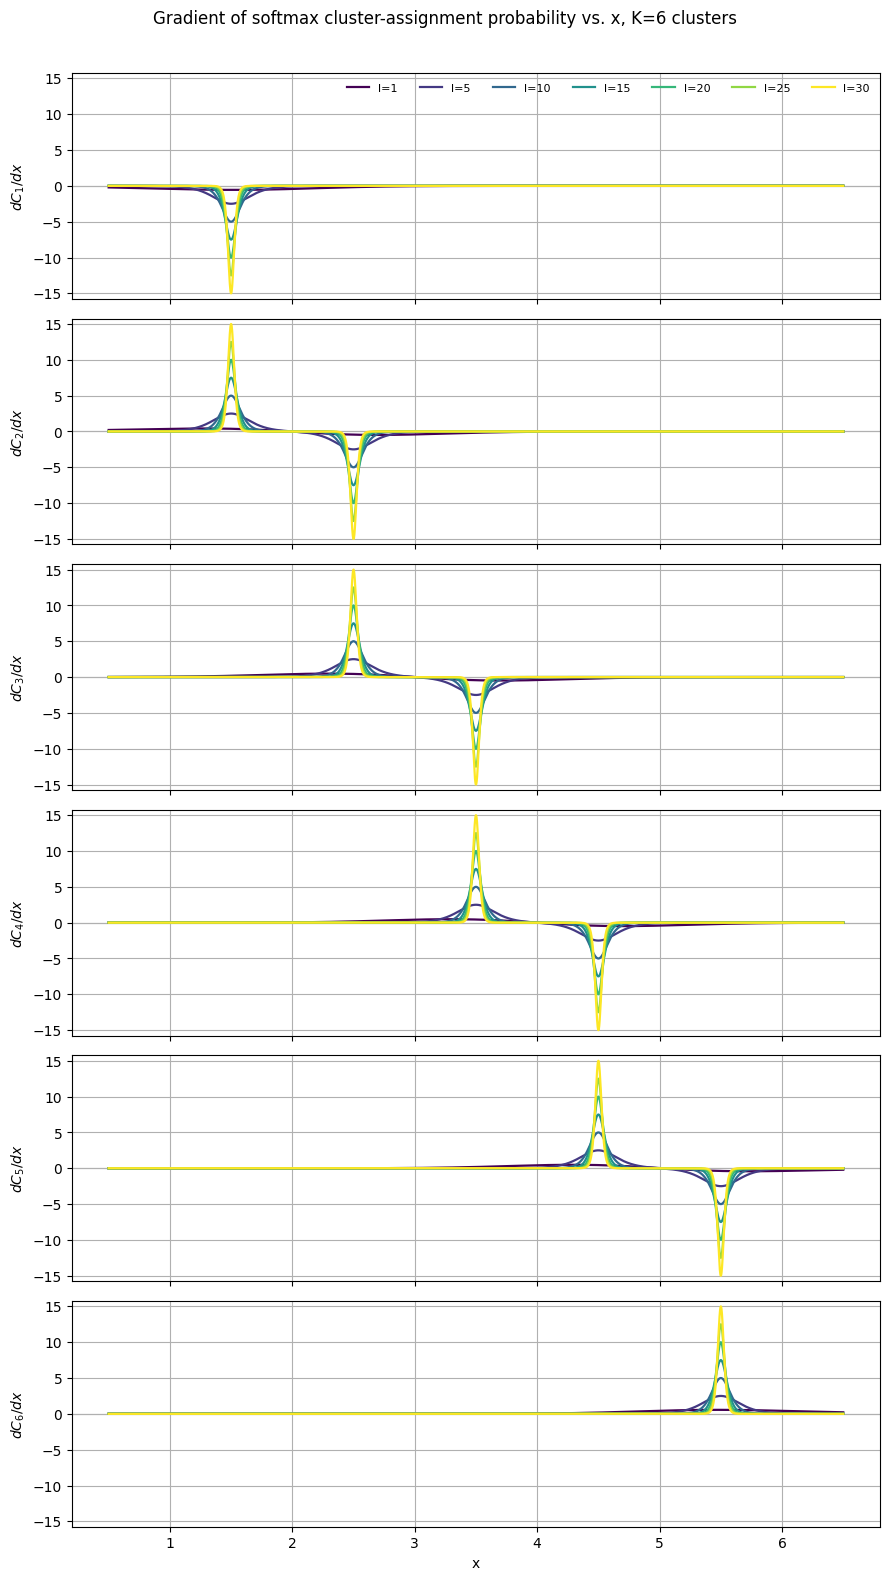

In [17]:
# global symmetric y-limit across all clusters and scales
grad_max = max(np.abs(grads[l]).max() for l in l_values)
ylim = 1.05 * grad_max  # small padding

fig, axes = plt.subplots(K, 1, figsize=(9, 2.6 * K), sharex=True)
if K == 1:
    axes = [axes]

colors = plt.cm.viridis(np.linspace(0, 1, len(l_values)))

for i, ax in enumerate(axes):
    for l, color in zip(l_values, colors):
        ax.plot(x_values, grads[l][:, i], label=f"l={l}", color=color, linewidth=1.6)
    ax.axhline(0, color="gray", lw=0.8, zorder=0)
    ax.set_ylabel(rf"$dC_{{{i+1}}}/dx$")
    ax.set_ylim(-ylim, ylim)
    ax.grid()

axes[0].legend(loc="upper right", ncol=len(l_values), fontsize=8, frameon=False)
axes[-1].set_xlabel("x")
fig.suptitle(
    f"Gradient of softmax cluster-assignment probability vs. x, K={K} clusters",
    y=1.01,
)
fig.tight_layout()


plt.show()

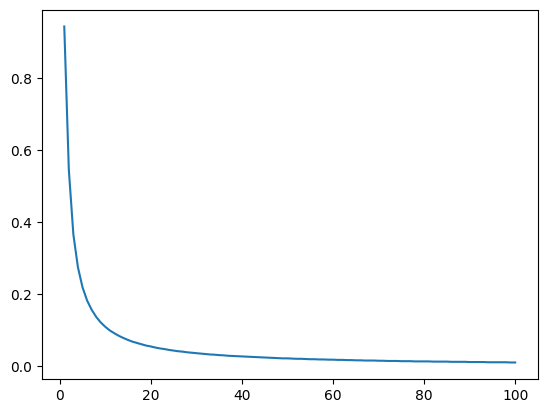

In [18]:
l_data =[]
distance_data = []
for i in range(1, 101):
    A = np.array([softmax_probs(x, cluster_positions, i) for x in x_values])
    C1 = A[:,-1]
    mask = (C1 >= 0.5) & (C1 <= 0.9)
    indices = np.where(mask)[0]        # the indices where the condition holds
    x_in_range = x_values[indices]     # the corresponding x values
    #print(x_in_range)
    if indices.size > 0:
        distance = x_in_range[-1] - x_in_range[0]
    else:
        distance = None  # never enters that probability range on this grid
    l_data.append(i)
    distance_data.append(distance)

plt.plot(l_data,distance_data)

In [19]:
import pandas as pd

df = pd.DataFrame({"l": l_data, "distance": distance_data})
df

,l,distance
0,1,0.942094
1,2,0.544854
2,3,0.364836
3,4,0.274227
4,5,0.219022
...,...,...
95,96,0.010801
96,97,0.010801
97,98,0.010801
98,99,0.010201


In [20]:
import numpy as np

col = df["distance"].to_numpy()
final = col[-1]

rtol = 0.01                                    # "almost the same" = within 1% of the final value
close = np.abs(col - final) <= rtol * abs(final)

# first index from which ALL later values are close (not just a single close point)
stays_close = np.flip(np.cumprod(np.flip(close))).astype(bool)
idx = int(np.argmax(stays_close)) if stays_close.any() else None

print("settles at index", idx, "->", df.iloc[idx].to_dict() if idx is not None else None)

settles at index 98 -> {'l': 99.0, 'distance': 0.010201020102010183}


## Why the transition narrows: `1/l`, not `1/sqrt(l)`

Near the boundary between two unit-spaced adjacent clusters, the
softmax logit difference is `l * (d1^2 - d2^2)`. Since the clusters are
a fixed distance apart, `d1^2 - d2^2` factors as `(d1-d2)(d1+d2)` where
`(d1+d2)` stays constant near the boundary -- so the expression is
*linear*, not quadratic, in the offset from the midpoint. That means
the distance needed to reach a given confidence level scales as `1/l`.

Solving for the distance from the exact boundary needed to reach 90%
confidence:

```
distance = ln(9) / (2 * l)
```

So doubling `l` exactly halves that distance -- verified numerically
below.

In [21]:
import pandas as pd

# Distance from the exact tie boundary (e.g. x=1.5 for C1/C2) needed to
# reach 90% confidence, measured directly from the computed curves vs.
# the closed-form ln(9)/(2l) prediction.
boundary_x = 1.5  # midpoint between cluster 1 and cluster 2
center_x = 2.0     # cluster 2's own center

rows = []
for l in l_values:
    if l == 0:
        continue
    fine_x = np.linspace(boundary_x, center_x, 5000)
    fine_probs = np.array([softmax_probs(x, cluster_positions, l)[1] for x in fine_x])
    idx = np.argmin(np.abs(fine_probs - 0.9))
    measured_dist = center_x - fine_x[idx]
    predicted_dist = np.log(9) / (2 * l)
    rows.append({"l": l, "measured_distance": round(measured_dist, 4),
                 "predicted_ln9_over_2l": round(predicted_dist, 4)})

pd.DataFrame(rows)


,l,measured_distance,predicted_ln9_over_2l
0,1,0.0229,1.0986
1,5,0.2800,0.2197
2,10,0.3902,0.1099
3,15,0.4268,0.0732
4,20,0.4451,0.0549
5,25,0.4561,0.0439
6,30,0.4634,0.0366


# prior mean = 2.3 , prior std = 0.3 , warmup samples = 100, posterior samples = 500, chain = 5
# Scale = 1

                mean       std    median      5.0%     95.0%     n_eff     r_hat
      mu_1      2.88      0.03      2.88      2.84      2.93    987.29      1.00

Number of divergences: 0
# Scale = 5

                mean       std    median      5.0%     95.0%     n_eff     r_hat
      mu_1      2.85      0.17      2.89      2.84      3.01     14.84      1.41

Number of divergences: 18
# scale = 10 

                mean       std    median      5.0%     95.0%     n_eff     r_hat
      mu_1      2.34      0.01      2.34      2.33      2.35    400.19      1.01

Number of divergences: 0
# scale = 15

                mean       std    median      5.0%     95.0%     n_eff     r_hat
      mu_1      2.32      0.02      2.33      2.29      2.35    246.64      1.01

Number of divergences: 5
# scale = 20

                mean       std    median      5.0%     95.0%     n_eff     r_hat
      mu_1      2.29      0.03      2.29      2.24      2.35    653.22      1.00

Number of divergences: 224
# scale = 25

                mean       std    median      5.0%     95.0%     n_eff     r_hat
      mu_1      2.28      0.04      2.28      2.23      2.35    552.96      1.00

Number of divergences: 206
# scale = 30

                mean       std    median      5.0%     95.0%     n_eff     r_hat
      mu_1      2.28      0.04      2.28      2.22      2.35    497.08      1.01

Number of divergences: 153

# scale = 1.00 ->  Elapsed time: 0:23:07.628800
# scale = 5.00 ->  Elapsed time: 0:37:47.318528
# scale = 10.0 ->  Elapsed time: 0:35:59.768216
# scale = 15.0 ->  Elapsed time: 0:37:31.748686
# scale = 20.0 ->  Elapsed time: 0:49:42.646551
# scale = 25.0 ->  Elapsed time: 0:58:50.012719
# scale = 30.0 ->  Elapsed time: 2:37:05.658349



In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# palette (consistent with earlier figures in this session)
ink = "#1a1a2e"
muted = "#6b7280"
hue = "#3b6fd4"
hue_good = "#2e7d32"
hue_bad = "#c0392b"
prior_c = "#9ca3af"

scale = np.array([1, 5, 10, 15, 20, 25, 30])
mean = np.array([2.88, 2.85, 2.34, 2.32, 2.29, 2.28, 2.28])
std = np.array([0.03, 0.17, 0.01, 0.02, 0.03, 0.04, 0.04])
n_eff = np.array([987.29, 14.84, 400.19, 246.64, 653.22, 552.96, 497.08])
r_hat = np.array([1.00, 1.41, 1.01, 1.01, 1.00, 1.00, 1.01])
divergences = np.array([0, 18, 0, 5, 224, 206, 153])

# elapsed times -> minutes
elapsed_str = {
    1: "0:23:07.628800",
    5: "0:37:47.318528",
    10: "0:35:59.768216",
    15: "0:37:31.748686",
    20: "0:49:42.646551",
    25: "0:58:50.012719",
    30: "2:37:05.658349",
}
def to_minutes(s):
    h, m, sec = s.split(":")
    return int(h) * 60 + int(m) + float(sec) / 60

elapsed_min = np.array([to_minutes(elapsed_str[s]) for s in scale])

prior_mean, prior_std = 2.3, 0.3

fig, axes = plt.subplots(3, 2, figsize=(15, 10))
fig.suptitle(
    r"$\beta$ sensitivity sweep — single-parameter ($\mu_2$), warmup=100, samples=500, chains=5",
    fontsize=20, color=ink, y=1.00
)

# Panel 1: mean +/- std with prior overlay
ax = axes[0, 0]
ax.axhspan(prior_mean - prior_std, prior_mean + prior_std, color=prior_c, alpha=0.2, label=r"Prior (±1 $\sigma$)")
ax.axhline(prior_mean, color=prior_c, lw=1.4, linestyle="--", label=r"Prior mean")
ax.errorbar(scale, mean, yerr=std, fmt="o-", color=hue, ecolor=hue, capsize=4, linewidth=1.8, markersize=6, label=r"Posterior $\mathbb{E}[\mu] \pm \sigma $")
ax.set_title(r"Posterior $\mathbb{E}[\mu] \pm \sigma $ vs. $\beta$", fontsize=15, color=ink)
ax.set_xlabel(r"$\beta$")
ax.set_ylabel(r"$\mu_2$")
ax.legend(fontsize=15, frameon=False)
ax.grid(alpha=0.3)

# Panel 2: r_hat
ax = axes[0, 1]
ax.plot(scale, r_hat, "o-", color=ink, linewidth=1.8, markersize=6)
ax.axhline(1.01, color=hue_good, lw=1.2, linestyle="--", alpha=0.7, label=r"$\hat{R}$ = 1.01 (common guideline)")
ax.set_title(r"$\hat{R}$ vs. $\beta$", fontsize=15, color=ink)
ax.set_xlabel(r"$\beta$")
ax.set_ylabel(r"$\hat{R}$")
ax.legend(fontsize=15, frameon=False)
ax.grid(alpha=0.3)

# Panel 3: n_eff
ax = axes[1, 0]
ax.plot(scale, n_eff, "o-", color=hue, linewidth=1.8, markersize=6)
ax.axhline(400, color=hue_good, lw=1.2, linestyle="--", alpha=0.8, label=r" $n_{eff}$ = 400")
ax.set_title(r"$n_{eff}$ vs. $\beta$", fontsize=15, color=ink)
ax.set_xlabel(r"$\beta$")
ax.set_ylabel(r"$n_{eff}$")
ax.legend(fontsize=15, frameon=False)
ax.grid(alpha=0.3)

# Panel 4: divergences (bar chart — see earlier discussion on bar vs. line)
ax = axes[1, 1]
ax.bar(scale, divergences, width=1.8, color=hue_bad, alpha=0.85)
ax.set_title(r"Number of divergences vs. $\beta$", fontsize=15, color=ink)
ax.set_xlabel(r"$\beta$")
ax.set_ylabel("divergences (out of 2500 draws)")
ax.grid(alpha=0.3, axis="y")
for s, d in zip(scale, divergences):
    ax.annotate(str(d), (s, d), textcoords="offset points", xytext=(0, 4), ha="center", fontsize=8, color=ink)

# Panel 5: wall-clock time
ax = axes[2, 0]
ax.plot(scale, elapsed_min, "o-", color=muted, linewidth=1.8, markersize=6)
ax.set_title(r"Wall-clock time vs. $\beta$", fontsize=15, color=ink)
ax.set_xlabel(r"$\beta$")
ax.set_ylabel("elapsed time (minutes)")
ax.grid(alpha=0.3)

# Panel 6: std alone (zoomed)
ax = axes[2, 1]
ax.plot(scale, std, "o-", color=hue, linewidth=1.8, markersize=6)
ax.axhline(prior_std, color=prior_c, lw=1.2, linestyle="--", label=r"prior $\sigma$ = 0.3")
ax.set_title(r"Posterior $\sigma$ vs. $\beta$", fontsize=15, color=ink)
ax.set_xlabel(r"$\beta$")
ax.set_ylabel(r"Posterior $\sigma$")
ax.legend(fontsize=15, frameon=False, loc="upper right", bbox_to_anchor=(1.0, 0.88))
ax.grid(alpha=0.3)

for ax in axes.flat:
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.savefig("scale_sweep_final_1to30.pdf", dpi=160, bbox_inches="tight", facecolor="white")


/var/folders/lr/h2867zhs72gcy61j6_cy0n0r0000gq/T/ipykernel_26966/3453585375.py:108: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
